# NISAR SAR Data — Exploratory Data Analysis

## Wildfire Monitoring: Burgohondo, Ávila, Spain

This notebook explores the potential of NISAR L-band Synthetic Aperture Radar (SAR) data for detecting surface changes associated with a wildfire near Burgohondo, Spain, which started on July 22, 2026.

The analysis uses two NISAR Level-2 Geocoded Polarimetric Covariance (GCOV) products acquired before and after the wildfire:

- **Before:** July 14, 2026
- **After:** August 19, 2026

Both acquisitions contain HH and HV polarization measurements, which provide information about how radar signals interact with the Earth's surface and vegetation.

### Objectives

The main objectives of this exploratory analysis are:

1. Examine the structure, spatial coverage, and quality of the NISAR GCOV data.
2. Compare radar backscatter characteristics before and after the wildfire.
3. Calculate changes in HH and HV backscatter, as well as the HH/HV polarization ratio.
4. Identify spatial patterns that may indicate vegetation disturbance or fire-related surface changes.
5. Explore whether the observed changes could support further wildfire detection and visualization.

The analysis is exploratory. Changes detected in SAR backscatter are not necessarily caused by fire, as they may also result from variations in soil moisture, vegetation conditions, or acquisition geometry. Additional validation using optical satellite data, such as Landsat-derived dNBR, will be needed to confirm the affected areas.

In [1]:
from pathlib import Path
import h5py
import numpy as np
import matplotlib.pyplot as plt
from pyproj import Transformer
import pandas as pd
from scipy.ndimage import median_filter


In [2]:
def to_db(data):
    arr = np.asarray(data, dtype=np.float32)
    result = np.full(arr.shape, np.nan, dtype=np.float32)

    valid = np.isfinite(arr) & (arr > 0)
    result[valid] = 10 * np.log10(arr[valid])

    return result

## 1. Data Loading and Initial Inspection

The input data consists of two NISAR Level-2 GCOV products stored in HDF5 format. These files contain geocoded radar measurements, associated geographic coordinates, and additional metadata.

We first identify the available files and inspect their internal structure to locate the datasets required for the analysis.

The main variables of interest are:

- **HHHH:** Radar backscatter power for HH polarization (horizontal transmission and horizontal reception).
- **HVHV:** Radar backscatter power for HV polarization (horizontal transmission and vertical reception).
- **xCoordinates, yCoordinates:** Spatial coordinates of the raster grid.
- **projection:** Coordinate reference system used by the product.

The GCOV diagonal covariance terms represent radar backscatter power in linear units. For visualization and comparison, these values are converted to decibels (dB) using:

$$
\sigma_{\mathrm{dB}} = 10 \log_{10}(P)
$$

where \(P\) represents the positive linear backscatter power.

Only finite, positive values are converted. Invalid values are represented as NaN and excluded from subsequent statistical calculations.

In [3]:
DATA_DIR = Path("data/raw")

files = sorted(DATA_DIR.glob("*.h5"))

print(f"Found {len(files)} HDF5 files:\n")

for file in files:
    print(f"{file.name}")
    print(f"Size: {file.stat().st_size / 1e9:.2f} GB\n")

Found 2 HDF5 files:

NISAR_L2_PR_GCOV_025_087_A_022_2005_DHDH_A_20260714T052401_20260714T052434_P05023_F_F_J_001.h5
Size: 1.87 GB

NISAR_L2_PR_GCOV_028_087_A_022_2005_DHDH_A_20260819T052400_20260819T052432_P05023_N_F_J_001.h5
Size: 1.83 GB



In [4]:
before_file = next(f for f in files if "20260714" in f.name)
after_file = next(f for f in files if "20260819" in f.name)

print("BEFORE:", before_file.name)
print("AFTER: ", after_file.name)

BEFORE: NISAR_L2_PR_GCOV_025_087_A_022_2005_DHDH_A_20260714T052401_20260714T052434_P05023_F_F_J_001.h5
AFTER:  NISAR_L2_PR_GCOV_028_087_A_022_2005_DHDH_A_20260819T052400_20260819T052432_P05023_N_F_J_001.h5


In [5]:
with h5py.File(before_file, "r") as f:

    def show_structure(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(f"{name} | shape={obj.shape} | dtype={obj.dtype}")

    f.visititems(show_structure)

science/LSAR/GCOV/grids/frequencyA/HHHH | shape=(17388, 17640) | dtype=float32
science/LSAR/GCOV/grids/frequencyA/HVHV | shape=(17388, 17640) | dtype=float32
science/LSAR/GCOV/grids/frequencyA/inputDataExceptionMask | shape=(17388, 17640) | dtype=uint8
science/LSAR/GCOV/grids/frequencyA/listOfCovarianceTerms | shape=(2,) | dtype=|S4
science/LSAR/GCOV/grids/frequencyA/listOfPolarizations | shape=(2,) | dtype=|S2
science/LSAR/GCOV/grids/frequencyA/mask | shape=(17388, 17640) | dtype=uint8
science/LSAR/GCOV/grids/frequencyA/numberOfLooks | shape=(17388, 17640) | dtype=float32
science/LSAR/GCOV/grids/frequencyA/numberOfSubSwaths | shape=() | dtype=uint8
science/LSAR/GCOV/grids/frequencyA/projection | shape=() | dtype=uint32
science/LSAR/GCOV/grids/frequencyA/rtcGammaToSigmaFactor | shape=(17388, 17640) | dtype=float32
science/LSAR/GCOV/grids/frequencyA/xCoordinateSpacing | shape=() | dtype=float64
science/LSAR/GCOV/grids/frequencyA/xCoordinates | shape=(17640,) | dtype=float64
science/LSAR

In [6]:
with h5py.File(before_file, "r") as f:
    base = "/science/LSAR/GCOV/grids/frequencyA"

    print("Available datasets:")
    print(list(f[base].keys()))

    hh = f[f"{base}/HHHH"]
    hv = f[f"{base}/HVHV"]

    print("\nHH:", hh.shape, hh.dtype)
    print("HV:", hv.shape, hv.dtype)

Available datasets:
['HHHH', 'HVHV', 'inputDataExceptionMask', 'listOfCovarianceTerms', 'listOfPolarizations', 'mask', 'numberOfLooks', 'numberOfSubSwaths', 'projection', 'rtcGammaToSigmaFactor', 'xCoordinateSpacing', 'xCoordinates', 'yCoordinateSpacing', 'yCoordinates']

HH: (17388, 17640) float32
HV: (17388, 17640) float32


HH valid pixels: 360671
HV valid pixels: 360671


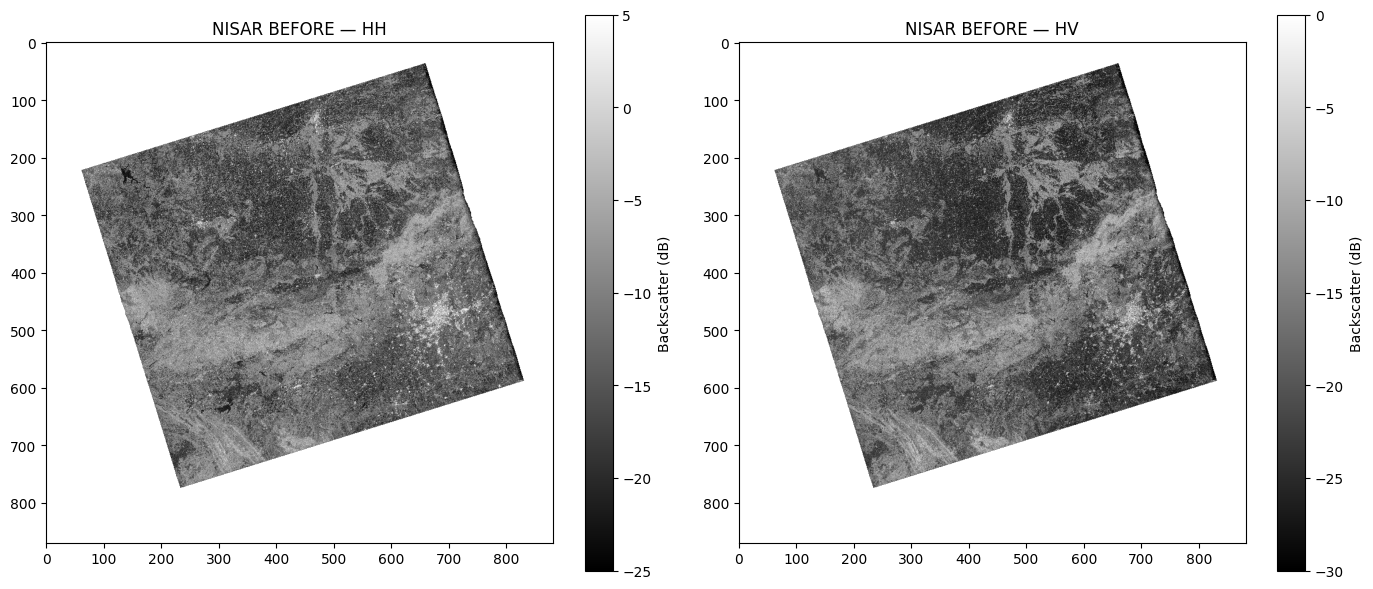

In [7]:
with h5py.File(before_file, "r") as f:
    base = "/science/LSAR/GCOV/grids/frequencyA"

    hh_sample = f[f"{base}/HHHH"][::20, ::20]
    hv_sample = f[f"{base}/HVHV"][::20, ::20]

hh_sample_db = to_db(hh_sample)
hv_sample_db = to_db(hv_sample)

print("HH valid pixels:", np.isfinite(hh_sample_db).sum())
print("HV valid pixels:", np.isfinite(hv_sample_db).sum())

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

im1 = axes[0].imshow(
    hh_sample_db,
    cmap="gray",
    vmin=-25,
    vmax=5
)
axes[0].set_title("NISAR BEFORE — HH")

im2 = axes[1].imshow(
    hv_sample_db,
    cmap="gray",
    vmin=-30,
    vmax=0
)
axes[1].set_title("NISAR BEFORE — HV")

plt.colorbar(im1, ax=axes[0], label="Backscatter (dB)")
plt.colorbar(im2, ax=axes[1], label="Backscatter (dB)")

plt.tight_layout()
plt.show()

In [8]:
with h5py.File(before_file, "r") as f:
    base = "/science/LSAR/GCOV/grids/frequencyA"

    x = f[f"{base}/xCoordinates"][:]
    y = f[f"{base}/yCoordinates"][:]

    projection = f[f"{base}/projection"][()]

    print("Projection EPSG:", projection)
    print("X range:", x.min(), x.max())
    print("Y range:", y.min(), y.max())
    print("X spacing:", x[1] - x[0])
    print("Y spacing:", y[1] - y[0])

Projection EPSG: 32630
X range: 169210.0 521990.0
Y range: 4316410.0 4664150.0
X spacing: 20.0
Y spacing: -20.0


## 2. Geographic Location and Area of Interest

The complete NISAR scenes contain approximately 307 million pixels per polarization, with a spatial resolution of 20 meters per pixel.

Processing the entire scene at full resolution would require substantial memory and computation. Therefore, two approaches are used:

- **Scene-wide exploration:** Spatial subsampling is applied to examine the overall backscatter distribution and identify large-scale changes.
- **Local analysis:** A smaller region around Burgohondo is extracted at the original spatial resolution for more detailed investigation.

### Coordinate transformation

The approximate geographic coordinates of the study area are:

- Latitude: 40.4° N
- Longitude: 4.8° W

The NISAR products use the projected coordinate system EPSG:32630 (WGS 84 / UTM Zone 30N). The geographic coordinates are transformed into this system to identify the corresponding raster pixel.

A window of 1000 × 1000 pixels is then extracted around the selected location, corresponding to an area of approximately 20 × 20 km.

The same pixel boundaries are applied to both acquisitions. Their coordinate grids are also compared to verify that corresponding pixels represent the same geographic locations.

**Note:** The selected crop is centered on an approximate location associated with the wildfire. It does not represent a verified fire perimeter, and some affected areas may lie outside this window.

In [9]:
# Burgohondo – współrzędne geograficzne
lon, lat = -4.8, 40.4

# WGS84 -> UTM Zone 30N
transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32630",
    always_xy=True
)

utm_x, utm_y = transformer.transform(lon, lat)

print(f"Burgohondo UTM: X={utm_x:.2f}, Y={utm_y:.2f}")

Burgohondo UTM: X=347248.75, Y=4473710.23


In [10]:
with h5py.File(before_file, "r") as f:
    base = "/science/LSAR/GCOV/grids/frequencyA"

    x = f[f"{base}/xCoordinates"][:]
    y = f[f"{base}/yCoordinates"][:]

col = np.argmin(np.abs(x - utm_x))
row = np.argmin(np.abs(y - utm_y))

print("Pixel row:", row)
print("Pixel col:", col)

Pixel row: 9522
Pixel col: 8902


In [11]:
half_size = 500

r0 = max(0, row - half_size)
r1 = min(len(y), row + half_size)

c0 = max(0, col - half_size)
c1 = min(len(x), col + half_size)

print("Crop rows:", r0, r1)
print("Crop cols:", c0, c1)

Crop rows: 9022 10022
Crop cols: 8402 9402


In [12]:
def load_crop(file_path, r0, r1, c0, c1):
    base = "/science/LSAR/GCOV/grids/frequencyA"

    with h5py.File(file_path, "r") as f:
        hh = f[f"{base}/HHHH"][r0:r1, c0:c1]
        hv = f[f"{base}/HVHV"][r0:r1, c0:c1]

    return hh, hv


hh_before, hv_before = load_crop(
    before_file, r0, r1, c0, c1
)

hh_after, hv_after = load_crop(
    after_file, r0, r1, c0, c1
)

In [13]:
with h5py.File(after_file, "r") as f:
    base = "/science/LSAR/GCOV/grids/frequencyA"
    x_after = f[f"{base}/xCoordinates"][:]
    y_after = f[f"{base}/yCoordinates"][:]
    epsg_after = int(f[f"{base}/projection"][()])

same_grid = (
    epsg_after == 32630
    and np.array_equal(x, x_after)
    and np.array_equal(y, y_after)
)

print("Same geographic grid:", same_grid)

Same geographic grid: True


BEFORE — HH: 999991 valid pixels
AFTER — HH: 999991 valid pixels
BEFORE — HV: 999991 valid pixels
AFTER — HV: 999991 valid pixels


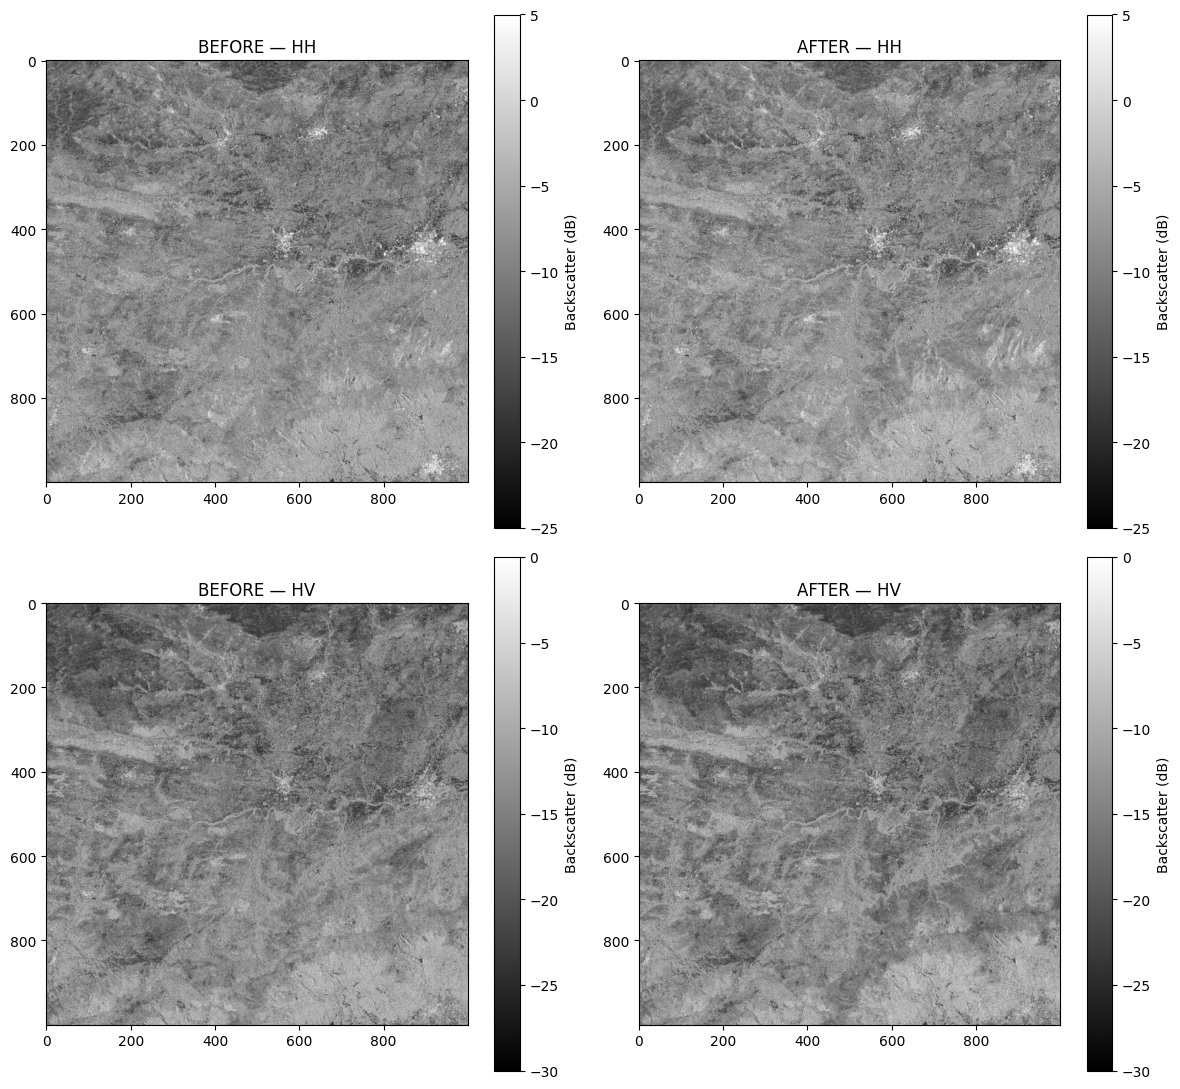

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 11))

images = [
    (hh_before, "BEFORE — HH", -25, 5),
    (hh_after, "AFTER — HH", -25, 5),
    (hv_before, "BEFORE — HV", -30, 0),
    (hv_after, "AFTER — HV", -30, 0)
]

for ax, (data, title, vmin, vmax) in zip(axes.flat, images):
    db = to_db(data)

    valid = np.isfinite(db).sum()
    print(f"{title}: {valid} valid pixels")

    im = ax.imshow(
        db,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )

    ax.set_title(title)
    plt.colorbar(im, ax=ax, label="Backscatter (dB)")

plt.tight_layout()
plt.show()

## 3. Data Quality Assessment and Descriptive Statistics

Before analyzing temporal changes, we examine the quality and statistical properties of both acquisitions.

### Metadata and grid consistency

The two products are compared in terms of raster dimensions, coordinate reference system, spatial resolution, and geographic grid alignment.

Both acquisitions have the same raster dimensions (17,388 × 17,640 pixels), use EPSG:32630, and have a pixel spacing of 20 meters.

Identical geographic grids allow direct pixel-wise comparison without additional spatial resampling.

### Missing and invalid values

The quality assessment identifies valid positive measurements, NaN values, zeros, negative values, and infinite values.

A substantial proportion of the raster contains missing values because the radar acquisition covers only part of the rectangular geocoded grid. These areas must be excluded from the analysis.

For the scene-wide sample, approximately 47% of pixels contain valid measurements in the before acquisition and 46% in the after acquisition.

### Backscatter distributions

Histograms and descriptive statistics are used to compare the distributions of HH and HV backscatter between the two dates.

The analysis includes the mean, median, standard deviation, minimum, maximum, and 5th and 95th percentiles.

The distributions overlap considerably, indicating that most of the observed scene has broadly similar backscatter characteristics across the two acquisitions.

However, global statistics may hide localized changes. A wildfire may affect only a relatively small portion of the scene, making spatial analysis particularly important.

# EDA

In [15]:
base = "/science/LSAR/GCOV/grids/frequencyA"

def get_metadata(file_path):
    with h5py.File(file_path, "r") as f:
        grid = f[base]

        return {
            "File": file_path.name,
            "Shape": grid["HHHH"].shape,
            "EPSG": int(grid["projection"][()]),
            "X spacing (m)": float(grid["xCoordinateSpacing"][()]),
            "Y spacing (m)": float(grid["yCoordinateSpacing"][()]),
            "HH dtype": str(grid["HHHH"].dtype),
            "HV dtype": str(grid["HVHV"].dtype),
        }

metadata = pd.DataFrame([
    get_metadata(before_file),
    get_metadata(after_file)
])

display(metadata)

,File,Shape,EPSG,X spacing (m),Y spacing (m),HH dtype,HV dtype
0,NISAR_L2_PR_GCOV_025_087_A_022_2005_DHDH_A_202...,"(17388, 17640)",32630,20.0,-20.0,float32,float32
1,NISAR_L2_PR_GCOV_028_087_A_022_2005_DHDH_A_202...,"(17388, 17640)",32630,20.0,-20.0,float32,float32


In [16]:
with h5py.File(before_file, "r") as f1, \
     h5py.File(after_file, "r") as f2:

    grid_before = f1[base]
    grid_after = f2[base]

    same_grid = (
        grid_before["projection"][()] == grid_after["projection"][()]
        and np.array_equal(
            grid_before["xCoordinates"][:],
            grid_after["xCoordinates"][:]
        )
        and np.array_equal(
            grid_before["yCoordinates"][:],
            grid_after["yCoordinates"][:]
        )
    )

print("Same geographic grid:", same_grid)

Same geographic grid: True


In [17]:
def load_sample(file_path, step=10):
    with h5py.File(file_path, "r") as f:
        grid = f[base]

        return {
            "HH": grid["HHHH"][::step, ::step],
            "HV": grid["HVHV"][::step, ::step]
        }

before = load_sample(before_file)
after = load_sample(after_file)

In [18]:
def quality_report(data, date):
    results = []

    for pol, arr in data.items():
        total = arr.size
        finite = np.isfinite(arr)
        positive = finite & (arr > 0)

        results.append({
            "Date": date,
            "Polarization": pol,
            "Total pixels": total,
            "Valid positive (%)": 100 * positive.sum() / total,
            "NaN (%)": 100 * np.isnan(arr).sum() / total,
            "Zero (%)": 100 * np.sum(arr == 0) / total,
            "Negative (%)": 100 * np.sum(arr < 0) / total,
            "Inf (%)": 100 * np.isinf(arr).sum() / total
        })

    return results

quality = pd.DataFrame(
    quality_report(before, "BEFORE") +
    quality_report(after, "AFTER")
)

display(quality.round(2))

,Date,Polarization,Total pixels,Valid positive (%),NaN (%),Zero (%),Negative (%),Inf (%)
0,BEFORE,HH,3067596,47.03,52.97,0.0,0.0,0.0
1,BEFORE,HV,3067596,47.03,52.97,0.0,0.0,0.0
2,AFTER,HH,3067596,45.65,54.35,0.0,0.0,0.0
3,AFTER,HV,3067596,45.65,54.35,0.0,0.0,0.0


In [19]:
before_db = {pol: to_db(arr) for pol, arr in before.items()}
after_db = {pol: to_db(arr) for pol, arr in after.items()}

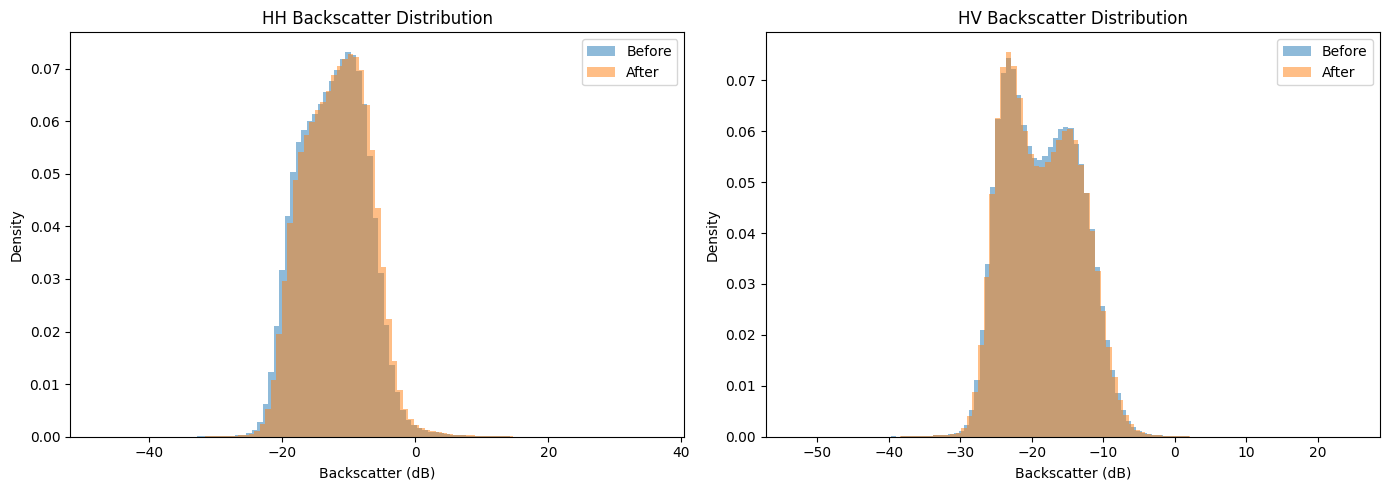

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, pol in zip(axes, ["HH", "HV"]):
    b = before_db[pol]
    a = after_db[pol]

    b = b[np.isfinite(b)]
    a = a[np.isfinite(a)]

    ax.hist(
        b, bins=100, density=True,
        alpha=0.5, label="Before"
    )
    ax.hist(
        a, bins=100, density=True,
        alpha=0.5, label="After"
    )

    ax.set_title(f"{pol} Backscatter Distribution")
    ax.set_xlabel("Backscatter (dB)")
    ax.set_ylabel("Density")
    ax.legend()

plt.tight_layout()
plt.show()

In [21]:
def describe_backscatter(data, date):
    results = []

    for pol, arr in data.items():
        values = arr[np.isfinite(arr)]

        if len(values) == 0:
            continue

        results.append({
            "Date": date,
            "Polarization": pol,
            "Mean (dB)": np.mean(values),
            "Median (dB)": np.median(values),
            "Std (dB)": np.std(values),
            "Min (dB)": np.min(values),
            "Max (dB)": np.max(values),
            "P5 (dB)": np.percentile(values, 5),
            "P95 (dB)": np.percentile(values, 95)
        })

    return results

stats = pd.DataFrame(
    describe_backscatter(before_db, "BEFORE") +
    describe_backscatter(after_db, "AFTER")
)

display(stats.round(3))

,Date,Polarization,Mean (dB),Median (dB),Std (dB),Min (dB),Max (dB),P5 (dB),P95 (dB)
0,BEFORE,HH,-12.288,-12.162,4.928,-47.737000,34.909000,-20.044001,-4.718
1,BEFORE,HV,-18.510,-18.740,5.140,-49.203999,23.905001,-25.985001,-10.148
2,AFTER,HH,-11.784,-11.673,4.917,-46.612000,36.243999,-19.525000,-4.220
3,AFTER,HV,-18.539,-18.826,5.178,-53.292000,24.834999,-26.014000,-10.091


## 4. Spatial Backscatter Patterns and Polarization Relationships

### HH and HV backscatter visualization

Backscatter maps are displayed for both acquisitions using consistent color scales for each polarization.

HH backscatter is influenced by surface roughness, terrain, and vegetation structure, while HV backscatter is particularly useful for examining volume scattering associated with vegetation.

Changes in vegetation structure after a wildfire may alter these scattering mechanisms.

### Valid data masks

Binary masks are created to identify pixels containing valid measurements.

These masks help distinguish actual radar observations from missing areas outside the acquisition footprint. For temporal comparisons, only pixels valid in both acquisitions are retained.

### HH and HV relationships

Hexagonal density plots are used to examine the relationship between HH and HV backscatter.

The plots show a positive relationship between the two polarizations, with considerable variation across the scene.

This relationship is useful because HH and HV respond differently to surface and vegetation properties. Comparing them may provide additional information beyond analyzing either polarization independently.

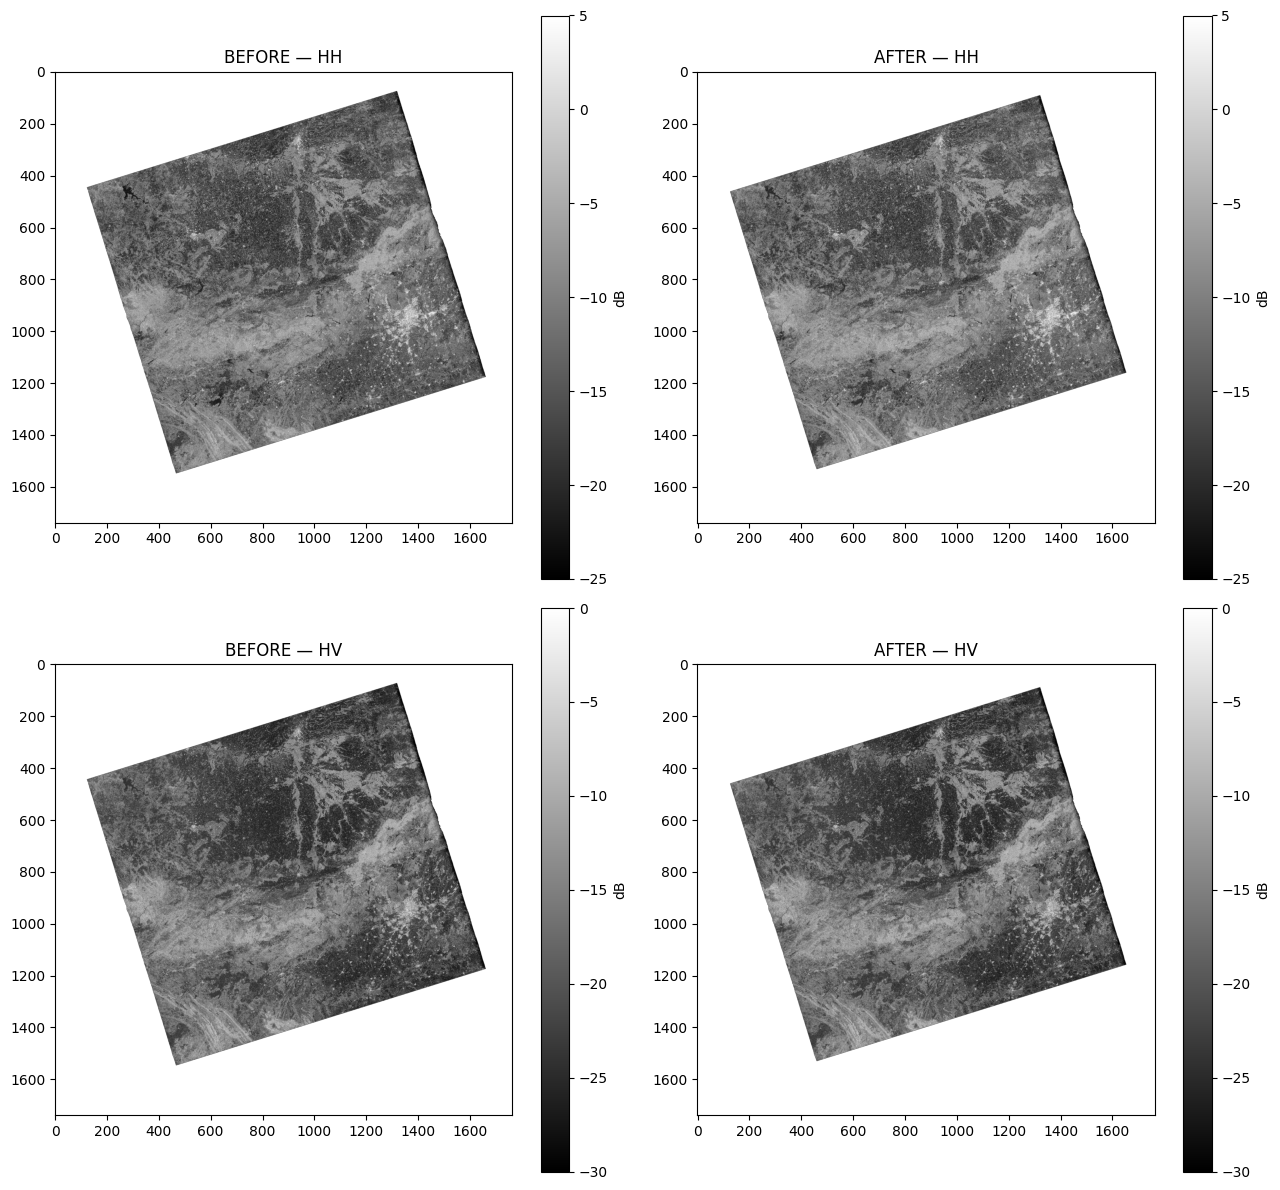

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 12))

for i, pol in enumerate(["HH", "HV"]):
    vmin, vmax = (-25, 5) if pol == "HH" else (-30, 0)

    for j, (date, data) in enumerate([
        ("BEFORE", before_db),
        ("AFTER", after_db)
    ]):
        ax = axes[i, j]

        im = ax.imshow(
            data[pol],
            cmap="gray",
            vmin=vmin,
            vmax=vmax
        )

        ax.set_title(f"{date} — {pol}")
        plt.colorbar(im, ax=ax, label="dB")

plt.tight_layout()
plt.show()

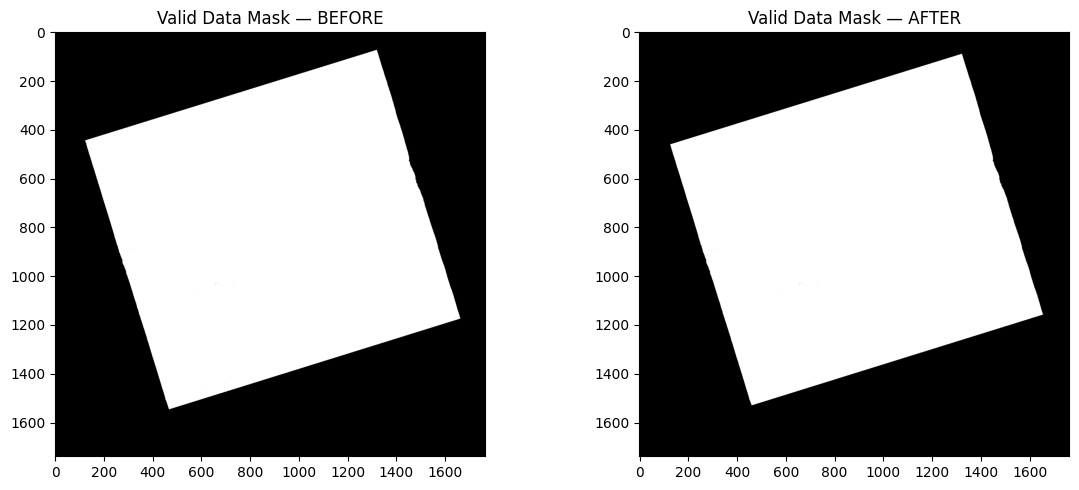

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, (date, data) in zip(
    axes,
    [("BEFORE", before), ("AFTER", after)]
):
    valid = (
        np.isfinite(data["HH"]) &
        np.isfinite(data["HV"]) &
        (data["HH"] > 0) &
        (data["HV"] > 0)
    )

    ax.imshow(valid, cmap="gray")
    ax.set_title(f"Valid Data Mask — {date}")

plt.tight_layout()
plt.show()

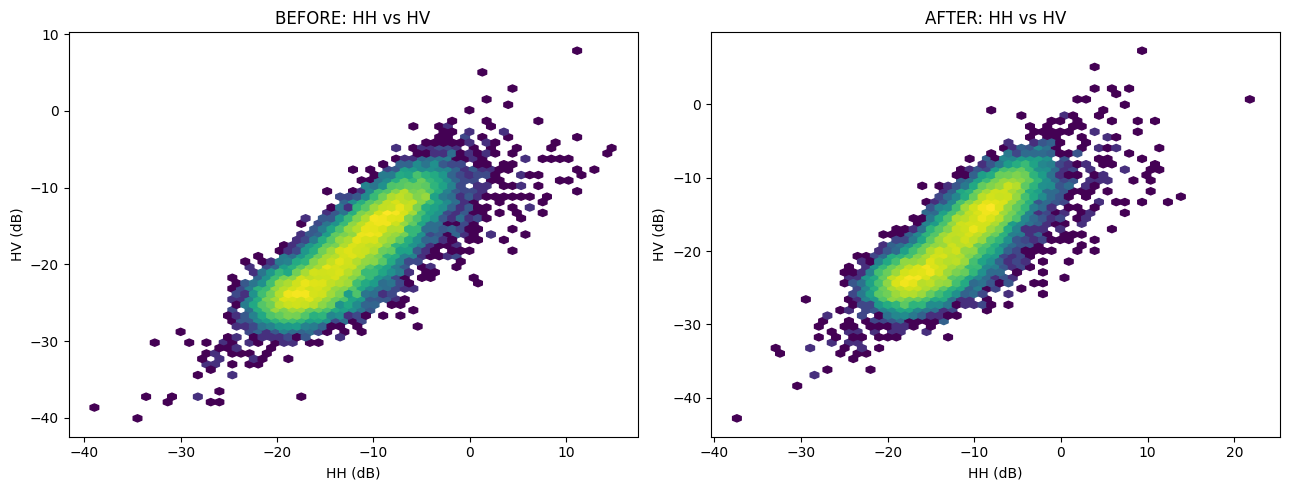

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (date, data) in zip(
    axes,
    [("BEFORE", before_db), ("AFTER", after_db)]
):
    hh = data["HH"].ravel()
    hv = data["HV"].ravel()

    valid = np.isfinite(hh) & np.isfinite(hv)

    hh = hh[valid]
    hv = hv[valid]

    # Limit points for visualization
    rng = np.random.default_rng(42)
    idx = rng.choice(
        len(hh),
        size=min(20000, len(hh)),
        replace=False
    )

    ax.hexbin(
        hh[idx],
        hv[idx],
        gridsize=60,
        bins="log",
        mincnt=1
    )

    ax.set_title(f"{date}: HH vs HV")
    ax.set_xlabel("HH (dB)")
    ax.set_ylabel("HV (dB)")

plt.tight_layout()
plt.show()

## 5. Temporal Change Detection

The main part of the analysis focuses on identifying differences between the pre-fire and post-fire NISAR acquisitions.

Three change indicators are calculated.

### HH backscatter change

$$
\Delta HH = HH_{\mathrm{after}} - HH_{\mathrm{before}}
$$

### HV backscatter change

$$
\Delta HV = HV_{\mathrm{after}} - HV_{\mathrm{before}}
$$

### HH/HV polarization ratio change

First, the polarization ratio is calculated in decibels:

$$
R = HH_{\mathrm{dB}} - HV_{\mathrm{dB}}
$$

The temporal difference is then calculated as:

$$
\Delta R = R_{\mathrm{after}} - R_{\mathrm{before}}
$$

This indicator describes changes in the relative contributions of HH and HV scattering.

### Interpretation

- **Positive values (red):** Increased backscatter or polarization ratio after the wildfire.
- **Negative values (blue):** Decreased backscatter or polarization ratio after the wildfire.
- **Values close to zero (white):** Relatively small differences between acquisitions.

These indicators are calculated using only pixels valid in both images.

The scene-wide analysis uses spatial subsampling, while the Burgohondo crop is processed at the original 20-meter pixel spacing.

The changes are not interpreted as a direct measure of fire severity. Their magnitude and direction depend on several environmental factors, and both increases and decreases in backscatter may occur following a wildfire.

In [25]:
# Common valid pixels
valid = (
    np.isfinite(before_db["HH"]) &
    np.isfinite(after_db["HH"]) &
    np.isfinite(before_db["HV"]) &
    np.isfinite(after_db["HV"])
)

# Backscatter differences in dB
delta_hh = after_db["HH"] - before_db["HH"]
delta_hv = after_db["HV"] - before_db["HV"]

# Polarization ratio in dB
ratio_before = before_db["HH"] - before_db["HV"]
ratio_after = after_db["HH"] - after_db["HV"]

delta_ratio = ratio_after - ratio_before

# Apply common mask
delta_hh[~valid] = np.nan
delta_hv[~valid] = np.nan
delta_ratio[~valid] = np.nan

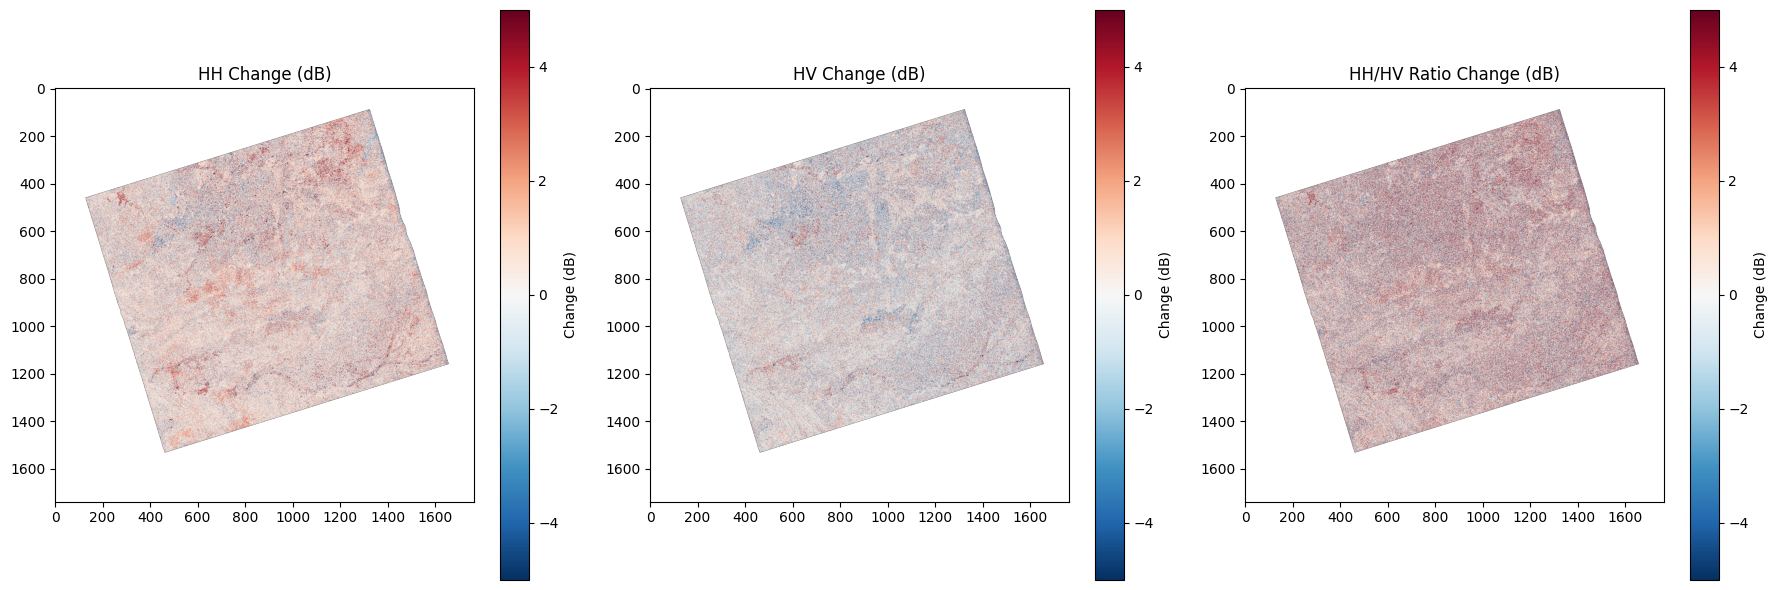

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

maps = [
    (delta_hh, "HH Change (dB)"),
    (delta_hv, "HV Change (dB)"),
    (delta_ratio, "HH/HV Ratio Change (dB)")
]

for ax, (data, title) in zip(axes, maps):
    im = ax.imshow(
        data,
        cmap="RdBu_r",
        vmin=-5,
        vmax=5
    )

    ax.set_title(title)
    plt.colorbar(im, ax=ax, label="Change (dB)")

plt.tight_layout()
plt.show()

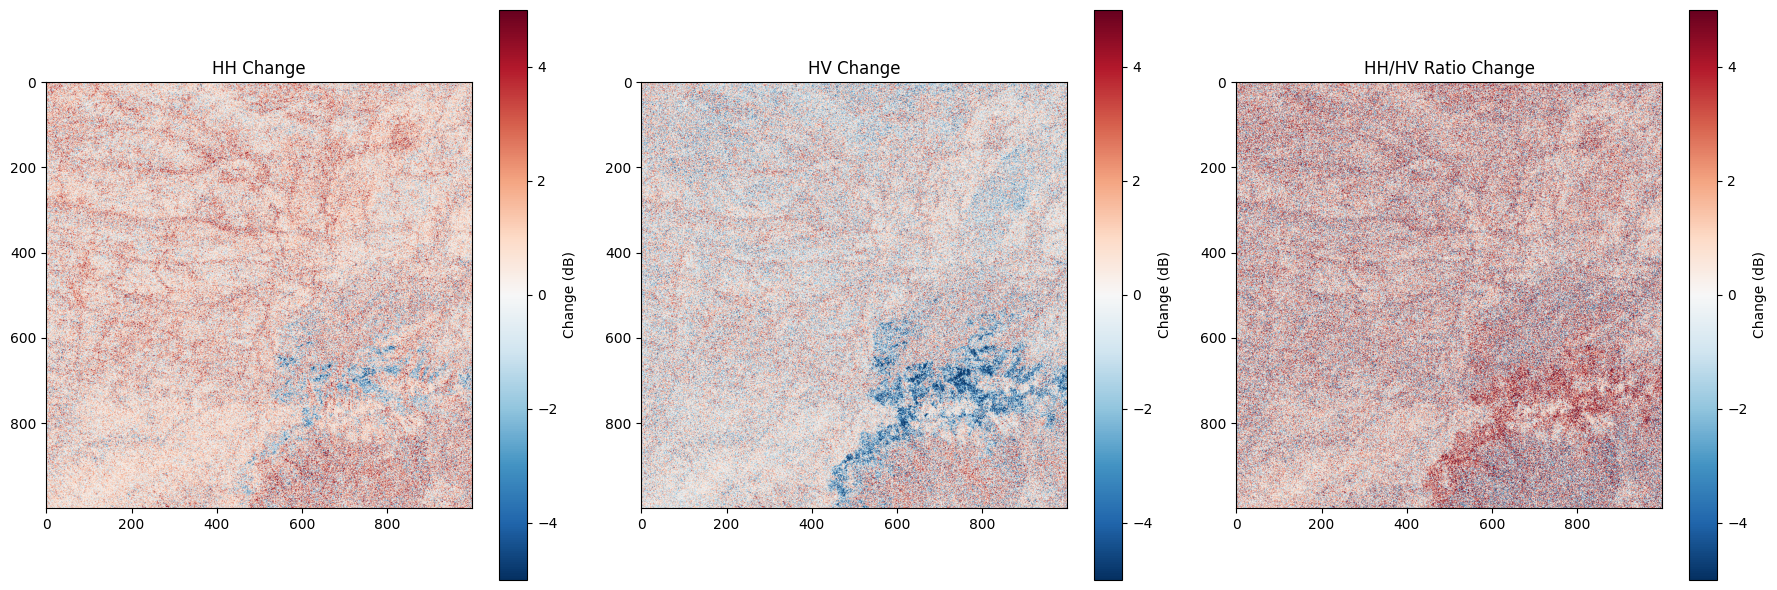

In [27]:
hh_before_db = to_db(hh_before)
hh_after_db = to_db(hh_after)

hv_before_db = to_db(hv_before)
hv_after_db = to_db(hv_after)

valid_crop = (
    np.isfinite(hh_before_db) &
    np.isfinite(hh_after_db) &
    np.isfinite(hv_before_db) &
    np.isfinite(hv_after_db)
)

delta_hh_crop = np.where(
    valid_crop, hh_after_db - hh_before_db, np.nan
)

delta_hv_crop = np.where(
    valid_crop, hv_after_db - hv_before_db, np.nan
)

delta_ratio_crop = delta_hh_crop - delta_hv_crop

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, data, title in zip(
    axes,
    [delta_hh_crop, delta_hv_crop, delta_ratio_crop],
    ["HH Change", "HV Change", "HH/HV Ratio Change"]
):
    im = ax.imshow(
        data,
        cmap="RdBu_r",
        vmin=-5,
        vmax=5
    )
    ax.set_title(title)
    plt.colorbar(im, ax=ax, label="Change (dB)")

plt.tight_layout()
plt.show()

In [28]:
for name, arr in [
    ("HH Change", delta_hh),
    ("HV Change", delta_hv),
    ("HH/HV Ratio Change", delta_ratio)
]:
    values = arr[np.isfinite(arr)]

    print(f"\n{name}")
    print(f"Mean: {np.mean(values):.3f} dB")
    print(f"Median: {np.median(values):.3f} dB")
    print(f"Std: {np.std(values):.3f} dB")
    print(f"P5: {np.percentile(values, 5):.3f} dB")
    print(f"P95: {np.percentile(values, 95):.3f} dB")


HH Change
Mean: 0.472 dB
Median: 0.450 dB
Std: 1.879 dB
P5: -2.468 dB
P95: 3.474 dB

HV Change
Mean: -0.072 dB
Median: -0.056 dB
Std: 1.948 dB
P5: -3.254 dB
P95: 3.057 dB

HH/HV Ratio Change
Mean: 0.544 dB
Median: 0.524 dB
Std: 2.527 dB
P5: -3.558 dB
P95: 4.714 dB


## 6. Spatial Smoothing and Potentially Affected Areas

SAR imagery contains speckle and small-scale spatial variability, which can make change maps difficult to interpret visually.

To emphasize more spatially consistent patterns, a 7 × 7 median filter is applied to the change maps within the Burgohondo crop.

The filter reduces isolated extreme values while preserving larger spatial structures. Missing pixels are excluded from the median calculation and remain masked in the output.

### Observed patterns

The smoothed maps reveal a spatially concentrated area of negative HV backscatter change in the lower-right portion of the selected crop.

A corresponding increase in the HH/HV polarization ratio is also visible in approximately the same region.

This combination is consistent with a relative reduction in cross-polarized scattering, which could be associated with changes in vegetation structure.

However, this pattern alone is insufficient to confirm wildfire damage. Other environmental changes, particularly differences in moisture conditions, may produce similar radar responses.

### Exploratory regional comparison

Two rectangular regions are selected for an initial comparison:

- **Suspected region:** An area containing pronounced spatial changes.
- **Reference region:** A separate area used to provide a preliminary comparison.

Median values of HH, HV, and HH/HV changes are calculated for both regions.

These regions were selected visually and are not independently verified fire boundaries or confirmed unaffected reference areas. Their comparison should therefore be treated as exploratory rather than as evidence of classification accuracy.

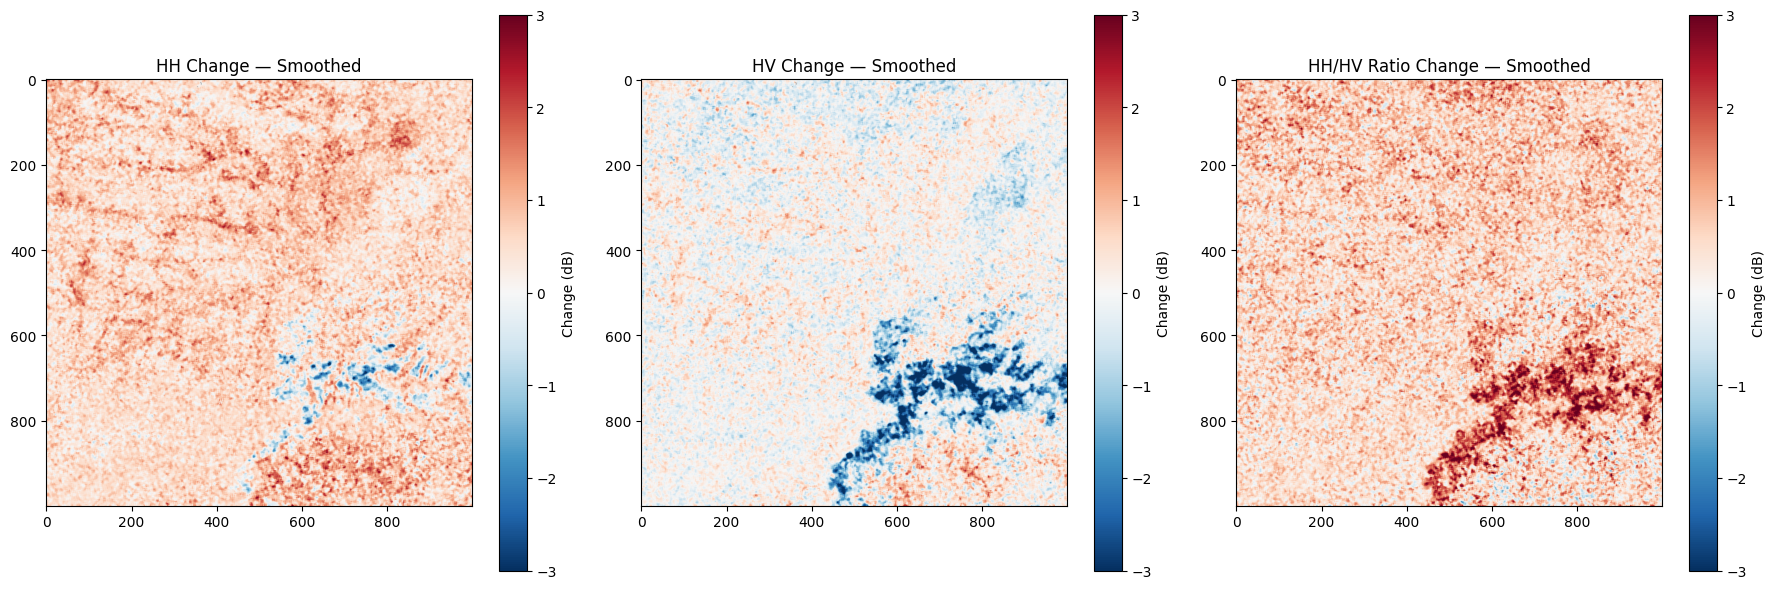

In [29]:
def smooth_change(data, size=7):
    valid = np.isfinite(data)

    # Median filter ignoring missing pixels
    from scipy.ndimage import generic_filter

    smoothed = generic_filter(
        data,
        function=lambda x: np.nanmedian(x) if np.isfinite(x).any() else np.nan,
        size=size
    )

    smoothed[~valid] = np.nan
    return smoothed

delta_hh_smooth = smooth_change(delta_hh_crop)
delta_hv_smooth = smooth_change(delta_hv_crop)
delta_ratio_smooth = smooth_change(delta_ratio_crop)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, data, title in zip(
    axes,
    [delta_hh_smooth, delta_hv_smooth, delta_ratio_smooth],
    ["HH Change — Smoothed",
     "HV Change — Smoothed",
     "HH/HV Ratio Change — Smoothed"]
):
    im = ax.imshow(
        data,
        cmap="RdBu_r",
        vmin=-3,
        vmax=3
    )

    ax.set_title(title)
    plt.colorbar(im, ax=ax, label="Change (dB)")

plt.tight_layout()
plt.show()

In [30]:
# Exploratory regions, not confirmed burn boundaries
suspected = np.s_[650:900, 600:950]
reference = np.s_[100:350, 100:450]

for name, data in [
    ("HH", delta_hh_crop),
    ("HV", delta_hv_crop),
    ("HH/HV", delta_ratio_crop)
]:
    s = data[suspected]
    r = data[reference]

    print(f"\n{name}")
    print("Suspected median:", np.nanmedian(s))
    print("Reference median:", np.nanmedian(r))


HH
Suspected median: 0.4081316
Reference median: 0.63374805

HV
Suspected median: -0.70912457
Reference median: 0.006192684

HH/HV
Suspected median: 1.146985
Reference median: 0.64601994


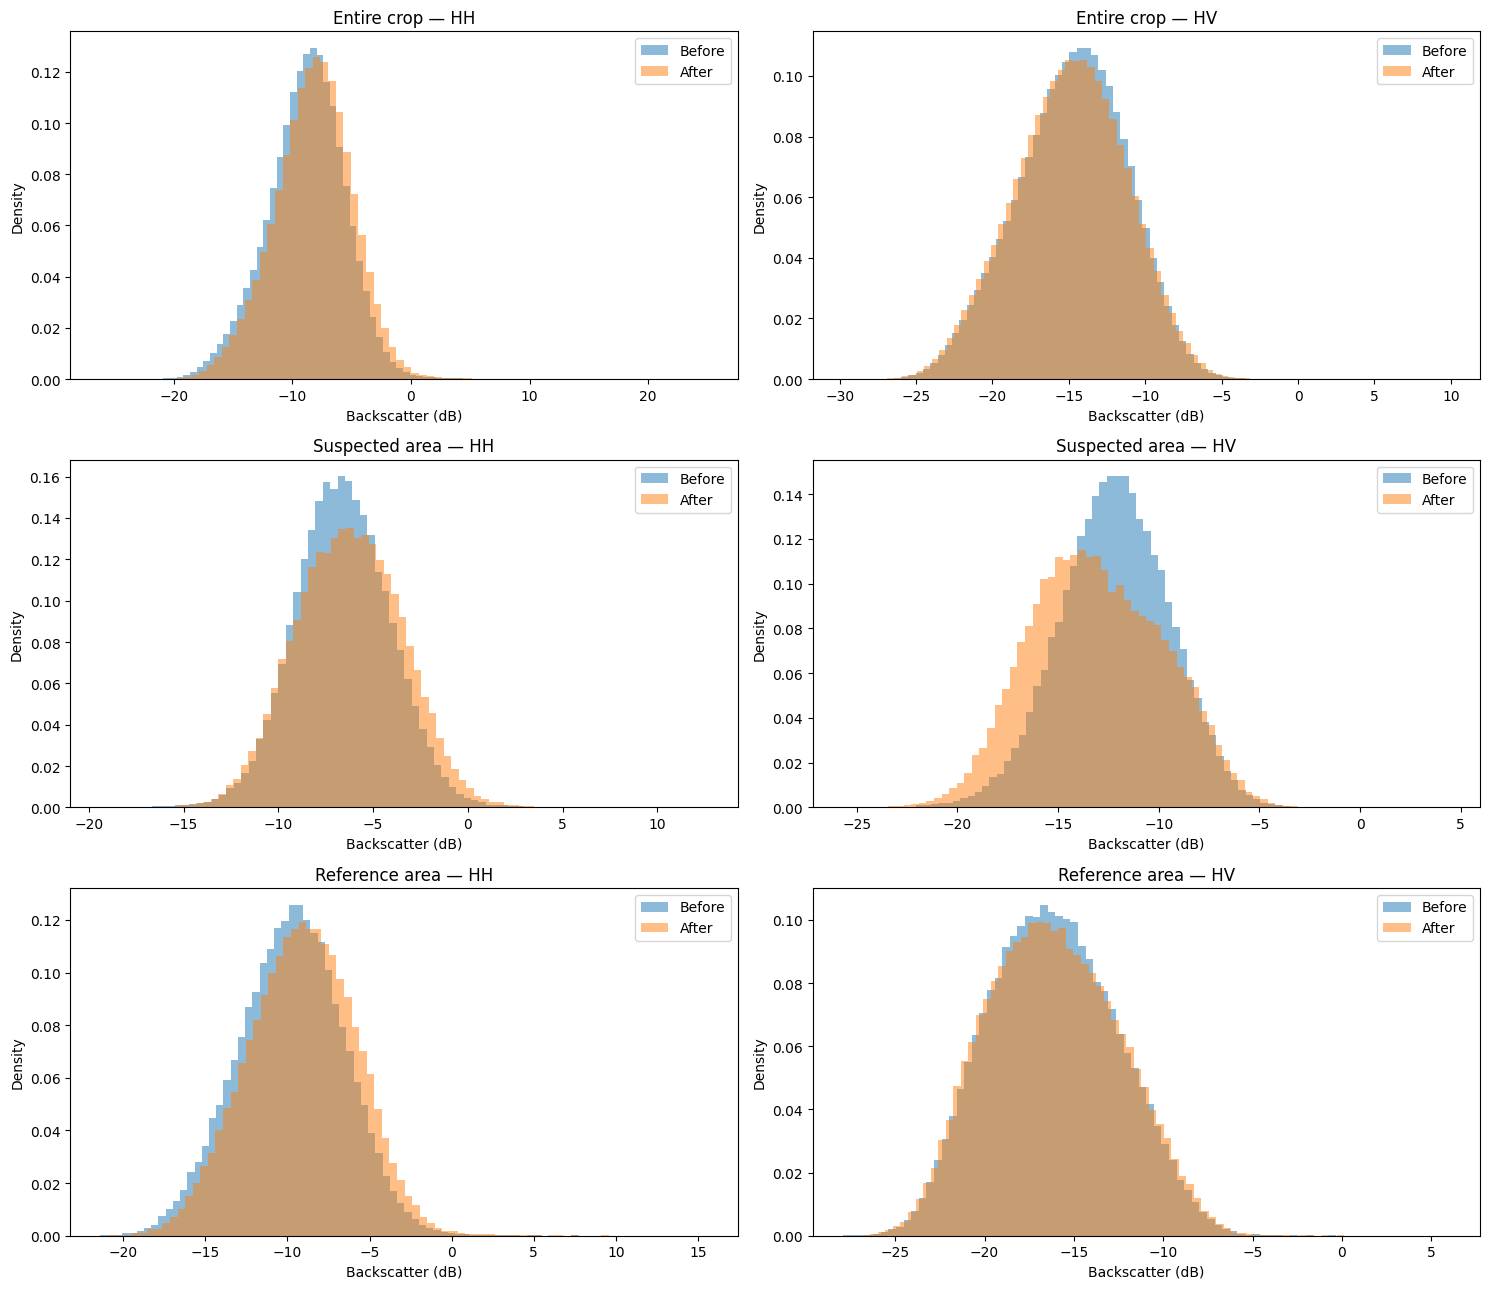

In [32]:
regions = {
    "Entire crop": np.s_[:, :],
    "Suspected area": np.s_[650:900, 600:950],
    "Reference area": np.s_[100:350, 100:450]
}

polarizations = {
    "HH": (hh_before_db, hh_after_db),
    "HV": (hv_before_db, hv_after_db)
}

fig, axes = plt.subplots(3, 2, figsize=(15, 13))

for i, (region_name, region) in enumerate(regions.items()):
    for j, (pol, (before_arr, after_arr)) in enumerate(polarizations.items()):

        ax = axes[i, j]

        b = before_arr[region]
        a = after_arr[region]

        # Use only pixels valid in both acquisitions
        valid = np.isfinite(b) & np.isfinite(a)

        b = b[valid]
        a = a[valid]

        ax.hist(
            b, bins=80, density=True,
            alpha=0.5, label="Before"
        )

        ax.hist(
            a, bins=80, density=True,
            alpha=0.5, label="After"
        )

        ax.set_title(f"{region_name} — {pol}")
        ax.set_xlabel("Backscatter (dB)")
        ax.set_ylabel("Density")
        ax.legend()

plt.tight_layout()
plt.show()